# Homework 3: VQGAN and NCSN

## Task 1: Theory (5 pts)

### Problem 1: Conjugate functions / f-GAN (1 pt)

The [f-GAN paper](https://arxiv.org/abs/1606.00709) presents a variational approach to training generative models with f-divergences. Here we use the following result without proof. For positive data and model densities,
$$
D_f(p_{\text{data}}\|p_{\boldsymbol\theta})
=\mathbb E_{p_{\boldsymbol\theta}}f\!\left(\frac{p_{\text{data}}(\mathbf x)}{p_{\boldsymbol\theta}(\mathbf x)}\right)
\ge\sup_{T\in\mathcal T}\left[\mathbb E_{p_{\text{data}}}T(\mathbf x)-\mathbb E_{p_{\boldsymbol\theta}}f^*(T(\mathbf x))\right],
$$
where
$$
f^*(t)=\sup_{u\in\operatorname{dom}(f)}\{ut-f(u)\}
$$
is the Fenchel conjugate. The critic $T$ takes values in the domain where $f^*$ is finite.

Maximization over an unrestricted critic class makes the bound tight in this setting. A restricted class $\mathcal T$ may give a strict lower bound: minimizing that bound over the generator does not by itself guarantee a decrease in the true divergence.

In this problem, derive the standard GAN objective from this variational expression. Consider
$$
f(u)=u\log u-(u+1)\log(u+1)+2\log2,
$$
with ordinary real logarithms. The additive constant ensures $f(1)=0$.

This choice gives $D_f(p_{\text{data}}\|p_{\boldsymbol\theta})=2D_{\mathrm{JS}}(p_{\text{data}}\|p_{\boldsymbol\theta})$, connecting the variational formulation to the Jensen–Shannon interpretation of GANs from the lecture. You may use this identity without proof.

- Find $\operatorname{dom}(f)$ for the expression as written.
- Show that
$$
f^*(t)=
\begin{cases}
-\log(1-e^t)-2\log2,&t<0,\\
+\infty,&t\ge0.
\end{cases}
$$
- Use the reparametrization $T(\mathbf x)=\log D_{\boldsymbol\phi}(\mathbf x)$, with $D_{\boldsymbol\phi}(\mathbf x)\in(0,1)$, to obtain the standard GAN objective up to an additive constant. Explain why the reparametrization covers the finite domain of $f^*$.


```your solution```

### Problem 2: Fréchet Inception Distance — isotropic Gaussian case (2 pts)

Prove the isotropic Gaussian special case of the Wasserstein formula from the lecture. This formula underlies FID, which compares Gaussian approximations to feature distributions; it is not the true Wasserstein distance between arbitrary feature distributions.

Recall the Wasserstein metric, for $s\ge1$:
$$
W_s(p_{\text{data}},p_{\boldsymbol\theta})=
\inf_{\gamma\in\Gamma(p_{\text{data}},p_{\boldsymbol\theta})}
\left(\mathbb E_{(\mathbf x,\mathbf y)\sim\gamma}\|\mathbf x-\mathbf y\|^s\right)^{1/s},
$$
where $\Gamma(p_{\text{data}},p_{\boldsymbol\theta})$ is the set of joint distributions with the specified marginals.

Consider
$$
\mathbf x\sim p_{\text{data}}=\mathcal N(\boldsymbol\mu_1,\sigma_1^2\mathbf I),\qquad
\mathbf y\sim p_{\boldsymbol\theta}=\mathcal N(\boldsymbol\mu_2,\sigma_2^2\mathbf I),
$$
where $\sigma_1,\sigma_2>0$ are standard deviations and $\mathbf x,\mathbf y\in\mathbb R^m$.

Prove that
$$
W_2^2(p_{\text{data}},p_{\boldsymbol\theta})=
\inf_{\gamma\in\Gamma(p_{\text{data}},p_{\boldsymbol\theta})}\mathbb E_{\gamma}\|\mathbf x-\mathbf y\|^2
=\|\boldsymbol\mu_1-\boldsymbol\mu_2\|^2+m(\sigma_1-\sigma_2)^2.
$$

Prove this result directly from the definition of $W_2$, without using the general Gaussian Wasserstein formula from the lecture.

**Hints (one possible approach):**
1. First consider $\boldsymbol\mu_1=\boldsymbol\mu_2=0$.
2. Use Cauchy–Schwarz to obtain a lower bound on the transport cost.
3. Find a mapping between $\mathbf x$ and $\mathbf y$ that attains this bound and has the required marginals.


```
your solution
```

### Problem 3: Implicit score matching (2 pts)

The score matching objective is
$$
\frac12\mathbb E_{p_{\text{data}}}\left\|\mathbf s_{\boldsymbol\theta}(\mathbf x)-\nabla_{\mathbf x}\log p_{\text{data}}(\mathbf x)\right\|_2^2\longrightarrow\min_{\boldsymbol\theta}.
$$
In the lecture, denoising score matching gave a computable objective for learning the score of the noise-perturbed data distribution. At a fixed positive noise level, this is generally different from the score of the original data distribution.

Here we derive another approach, **implicit score matching**, directly for the data distribution under suitable smoothness and boundary assumptions.

Consider the one-dimensional case, $x\in\mathbb R$. Assume that $p_{\text{data}}$ is positive and continuously differentiable, $s_{\boldsymbol\theta}$ is continuously differentiable, all expectations below are finite, and
$$
p_{\text{data}}(x)s_{\boldsymbol\theta}(x)\longrightarrow0
\quad\text{as }x\longrightarrow\pm\infty.
$$
Prove that
$$
\frac12\mathbb E_{p_{\text{data}}}\left(s_{\boldsymbol\theta}(x)-\partial_x\log p_{\text{data}}(x)\right)^2
=\mathbb E_{p_{\text{data}}}\left[\frac12s_{\boldsymbol\theta}(x)^2+\partial_xs_{\boldsymbol\theta}(x)\right]+C,
$$
where $C$ does not depend on $\boldsymbol\theta$.

**Discussion (no additional proof required):**
- What unknown quantity is no longer needed on the right-hand side, and what access to the data distribution is still required?
- What computational cost can make implicit score matching less convenient than denoising score matching in high dimensions?
- Is the method restricted to one dimension?


```
your solution
```

In [ ]:
COMMIT_HASH = "6d3b720afc1f41e7009b7b67450e8ac58327964d"
!if [ -d dgm_utils ]; then rm -Rf dgm_utils; fi
!git clone https://github.com/r-isachenko/dgm_utils.git
%cd dgm_utils
!git checkout {COMMIT_HASH}
!pip install ./
%cd ./..
!rm -Rf dgm_utils

In [2]:
from dgm_utils import train_model, train_adversarial
from dgm_utils import show_samples, visualize_images, load_dataset
from dgm_utils import BaseModel

In [ ]:
from typing import List, Tuple, Optional 

import math
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data

if torch.cuda.is_available():
    DEVICE = "cuda"
    print('GPU found :)')
else:
    DEVICE = "cpu"
    print('GPU not found :(')

## Task 2: VQGAN on CIFAR10 (4 pts)

In this task you will implement a [VQGAN](https://arxiv.org/abs/2012.09841) model for the CIFAR10 dataset. In Homework 2, we trained VQ-VAE using a pixel-wise reconstruction loss. However, quantization discards some image information, and minimizing MSE can encourage the decoder to average plausible reconstructions, producing blurred edges and textures.

VQGAN adds a discriminator that learns to distinguish real images from reconstructions. The reconstruction loss keeps the output close to the input, while the adversarial loss encourages realistic image structure and details.

Let us download and visualize samples from the dataset.

In [ ]:
train_data, _, test_data, _ = load_dataset("cifar10", flatten=False, binarize=False)
visualize_images(train_data, "CIFAR10 samples")

### Architecture

Let us start with the Transformer block. We will use the same ViT encoder and decoder as in Homework 2.

In [ ]:
class TransformerBlock(nn.Module):
    def __init__(
            self, 
            embed_dim: int, 
            num_heads: int,
            # this is for conviniance
            attention_class: nn.Module = nn.MultiheadAttention,
        ) -> None:
        super().__init__()
        assert embed_dim % num_heads == 0

        self.mha = attention_class(
            embed_dim, num_heads, batch_first=True
        )
        # ====
        # your code
        # define basic layers of Transformer:
        # 1) LayerNorm (https://docs.pytorch.org/docs/stable/generated/torch.nn.LayerNorm.html)
        # 2) some MLP
        
        # ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # here you have to implement formulas that described above.
        
        # ====
        return x


def test_transformer_block() -> None:
    block = TransformerBlock(embed_dim=12, num_heads=4)
    x = torch.zeros(4, 28, 12)
    assert x.shape == block(x).shape

test_transformer_block()

Next, we define two projection layers that map images to sequences of flattened patches and reconstruct them back to the image space.

In [ ]:
class PatchProjection(nn.Module):
    def __init__(
        self, num_channels: int, dim: int, patch_shape: Tuple[int, int], 
    ):
        super().__init__()
        self.proj = nn.Conv2d(
            num_channels, dim, kernel_size=patch_shape, stride=patch_shape
        )

    def forward(self, x: torch.Tensor):
        # ====
        # your code
        # do following
        # 1) convolution with kernel_size=stride=patch_shape:
        #      splits the image into non-overlapping patches 
        #      and projects each patch to `dim`
        #      (B, C, H, W) -> (B, dim, H', W'),
        #      where H' = H // P_h and W' = W // P_w
        # 2) flatten patch grid to tokens:
        #      (B, dim, H', W') -> (B, dim, N), where N = H' * W'
        # 3) transpose to token-major format:
        #      (B, dim, N) -> (B, N, dim)
        
        # ====
        return x

class ImageProjection(nn.Module):
    def __init__(
        self, 
        dim: int,
        num_channels: int,
        patch_shape: Tuple[int, int], 
        image_shape: Tuple[int, int],
    ):
        super().__init__()
        self.num_channels = num_channels
        self.patch_shape = patch_shape
        self.image_shape = image_shape

        patch_dim = num_channels * patch_shape[0] * patch_shape[1]
        self.proj = nn.Linear(dim, patch_dim)

        self.refine = nn.Sequential(*[
            nn.Conv2d(num_channels, 2 * num_channels, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv2d(2 * num_channels, 2 * num_channels, kernel_size=3, padding=1),
            nn.GELU(),
            nn.Conv2d(2 * num_channels, num_channels, kernel_size=1)
        ])

    def forward(self, x: torch.Tensor):
        # ====
        # your code
        # 1) project each token back to patch pixels:
        #      (B, N, dim) -> (B, N, C * P_h * P_w)
        # 2) restore patch grid and patch shape:
        #      (B, N, C * P_h * P_w) -> (B, H', W', P_h, P_w, C)
        # 3) move channels first and interleave grid with patch pixels:
        #      (B, H', W', P_h, P_w, C) -> (B, C, H', P_h, W', P_w)
        # 4) Merge dimensions to reconstruct the image:
        #      (B, C, H', P_h, W', P_w) -> (B, C, H, W)
        # 5) apply CNN to reduce blocky patch artifacts
        
        # ====
        return x
    
def test_patch_and_image_projection():
    x = torch.zeros((2, 3, 32, 32))
    patch_shape = (8, 8)
    image_shape = (32, 32)
    dim = 64
    num_channels = 3

    patch_projection = PatchProjection(
        num_channels=num_channels, dim=dim, patch_shape=patch_shape
    )
    image_projection = ImageProjection(
        dim=dim,
        num_channels=num_channels,
        patch_shape=patch_shape,
        image_shape=image_shape,
    )

    tokens = patch_projection(x)
    assert tokens.shape == (2, 16, dim), (
        f"PatchProjection.forward returned wrong shape: got {tuple(tokens.shape)}, "
        f"expected (2, 16, {dim}). Input x shape was {tuple(x.shape)}, "
        f"patch_shape={patch_shape} gives 4x4=16 patches for image_shape={image_shape}."
    )

    decoded = image_projection(tokens)
    assert decoded.shape == (2, num_channels, *image_shape), (
        f"ImageProjection.forward returned wrong shape: got {tuple(decoded.shape)}, "
        f"expected (2, {num_channels}, {image_shape[0]}, {image_shape[1]}). "
        f"Tokens shape was {tuple(tokens.shape)}."
    )

test_patch_and_image_projection()

Now we can define Encoder and Decoder.

In [ ]:
class ViTEncoder(nn.Module):
    def __init__(
        self,
        num_channels: int,
        image_shape: Tuple[int, int],
        patch_shape: Tuple[int, int],
        embed_dim: int, 
        num_heads: int,
        num_layers: int,
    ) -> None:
        super().__init__()

        assert (image_shape[0] % patch_shape[0] == 0 and image_shape[1] % patch_shape[1] == 0), \
            "Image dimensions must be divisible by the patch size."

        num_patches = (image_shape[0] // patch_shape[0]) * (image_shape[1] // patch_shape[1])

        # ====
        # your code
        # define here:
        # 1) patch projection using `PatchProjection`
        # 2) positional embeddings 
        #      use nn.Parameter with shape (1, num_patches, embed_dim)
        # 3) transformer using `TransformerBlock`
        
        # ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # apply here defined networks
        # NOTE: positional embeddins are just summed with projected x 
        
        # ====
        return x
    
def test_vit_encoder():
    x = torch.zeros((2, 3, 32, 32))
    num_channels = 3
    image_shape = (32, 32)
    patch_shape = (8, 8)
    embed_dim = 64
    num_heads = 1
    num_layers = 2

    encoder = ViTEncoder(
        num_channels=num_channels,
        image_shape=image_shape,
        patch_shape=patch_shape,
        embed_dim=embed_dim,
        num_heads=num_heads,
        num_layers=num_layers,
    )

    tokens = encoder(x)
    assert tokens.shape == (2, 16, embed_dim), (
        f"ViTEncoder.forward returned wrong shape: got {tuple(tokens.shape)}, "
        f"expected (2, 16, {embed_dim}). Input x shape was {tuple(x.shape)}. "
        f"image_shape={image_shape}, patch_shape={patch_shape} implies num_patches="
        f"{(image_shape[0] // patch_shape[0]) * (image_shape[1] // patch_shape[1])}."
    )

test_vit_encoder()

In [ ]:
class ViTDecoder(nn.Module):
    def __init__(
        self,
        num_channels: int,
        image_shape: Tuple[int, int],
        patch_shape: Tuple[int, int],
        embed_dim: int, 
        num_heads: int,
        num_layers: int,
    ) -> None:
        super().__init__()

        assert (image_shape[0] % patch_shape[0] == 0 and image_shape[1] % patch_shape[1] == 0), \
            "Image dimensions must be divisible by the patch size."

        num_patches = (image_shape[0] // patch_shape[0]) * (image_shape[1] // patch_shape[1])

        # ====
        # your code
        # define here:
        # 1) positional embeddings
        #      use nn.Parameter with shape (1, num_patches, embed_dim)
        # 2) transformer using `TransformerBlock`
        # 3) image projection using `ImageProjection`
        
        # ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # apply here defined networks
        # NOTE: positional embeddins are just summed with projected x 
        
        # ====
        return x
    
def test_vit_decoder():
    x = torch.zeros((2, 16, 64))
    num_channels = 3
    image_shape = (32, 32)
    patch_shape = (8, 8)
    embed_dim = 64
    num_heads = 1
    num_layers = 2

    decoder = ViTDecoder(
        num_channels=num_channels,
        image_shape=image_shape,
        patch_shape=patch_shape,
        embed_dim=embed_dim,
        num_heads=num_heads,
        num_layers=num_layers,
    )

    decoded = decoder(x)
    assert decoded.shape == (2, num_channels, *image_shape), (
        f"ViTDecoder.forward returned wrong shape: got {tuple(decoded.shape)}, "
        f"expected (2, {num_channels}, {image_shape[0]}, {image_shape[1]}). "
        f"Input x shape was {tuple(x.shape)}. "
        f"Expected x to be (B, num_patches, embed_dim) with num_patches="
        f"{(image_shape[0] // patch_shape[0]) * (image_shape[1] // patch_shape[1])} "
        f"and embed_dim={embed_dim}."
    )

test_vit_decoder()

Now, let us implement the vector quantizer. It maps encoder outputs to the nearest codebook entries and computes the codebook and commitment losses.

In [ ]:
class VectorQuantizer(nn.Module):
    def __init__(
        self, num_embeddings: int = 128, embedding_dim: int = 16, beta: float = 0.25
    ) -> None:
        super().__init__()
        self.embedding_dim = embedding_dim
        self.num_embeddings = num_embeddings

        self.beta = beta

        # Initialize the embeddings which we will quantize.
        self.embedding = nn.Embedding(num_embeddings, embedding_dim)
        self.embedding.weight.data.uniform_(-1 / num_embeddings, 1 / num_embeddings)

    def get_code_indices(self, x: torch.Tensor) -> torch.Tensor:
        input_shape = x.shape[:-1]
        flattened = x.reshape(-1, self.embedding_dim)
        # ====
        # your code
        # 1) calculate distances from flatten inputs to embeddings
        # 2) find nearest embeddings to each input (use argmin op)
        
        # ====
        encoding_indices = encoding_indices.reshape(input_shape)
        return encoding_indices

    def get_quantized(self, encoding_indices: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # get embeddgins with appropriate indices
        
        # ====
        return quantized

    def forward(self, x: torch.Tensor) -> tuple:
        # ====
        # your code
        # 1) get indices
        # 2) get quantized latents
        # 3) calculate codebook and commitment loss
        #    do not afraid about stop_gradient op
        #    (use .detach() method for quantized latents and x)
        # 4) final loss is codebook_loss + beta * commitment_loss
        
        # ====

        # Straight-through estimator (think about it!).
        quantized = x + (quantized - x).detach()

        return quantized, loss

def test_vector_quantizer_tokens():
    x = torch.zeros((4, 16, 32))
    layer = VectorQuantizer(num_embeddings=128, embedding_dim=32)

    indices = layer.get_code_indices(x)
    assert indices.shape == (4, 16), (
        f"get_code_indices(x) returned wrong shape: got {tuple(indices.shape)}, "
        f"expected (4, 16). Input x shape was {tuple(x.shape)}."
    )

    quantized = layer.get_quantized(indices)
    assert quantized.shape == (4, 16, 32), (
        f"get_quantized(indices) returned wrong shape: got {tuple(quantized.shape)}, "
        f"expected (4, 16, 32). Indices shape was {tuple(indices.shape)}."
    )

    quantized, loss = layer(x)
    assert quantized.shape == (4, 16, 32), (
        f"layer(x) returned quantized with wrong shape: got {tuple(quantized.shape)}, "
        f"expected (4, 16, 32). Input x shape was {tuple(x.shape)}."
    )
    assert loss.shape == (), (
        f"layer(x) returned loss with wrong shape: got {tuple(loss.shape)}, "
        f"expected scalar shape (). Loss type was {type(loss)}."
    )

test_vector_quantizer_tokens()

Finally, let us define our discriminator. We will use a residual convolutional network with the following structure:

* Each residual block applies convolutions, normalization and `LeakyReLU` activations, then adds a shortcut connection.
* The first two blocks reduce the spatial resolution using average pooling. If a block changes the resolution or number of channels, we also transform its shortcut to match the output shape.
* After four residual blocks, we apply `LeakyReLU`, average the features over the spatial dimensions and use a linear layer to produce one score per image.

**NOTE:** do not use a sigmoid activation at the end, since we will use hinge loss for training!

In [ ]:
def avg_pool2d(x: torch.Tensor) -> torch.Tensor:
    return (x[:, :, ::2, ::2] + x[:, :, 1::2, ::2] + x[:, :, ::2, 1::2] + x[:, :, 1::2, 1::2]) / 4

class CriticBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, downsample=False, first=False):
        super().__init__()

        self.downsample = downsample
        self.first = first

        if in_channels != out_channels:
            self.shortcut_conv = nn.Conv2d(in_channels, out_channels, kernel_size=1)
        else:
            self.shortcut_conv = None
        # ====
        # your code
        # define the layers if block is first do not define ReLU
        
        # ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # 1) create shortcut: if downsample is True, apply avg_pool
        # 2) if shortcut_conv is not None, apply it
        # 3) apply main conv layers to x
        # NOTE: do not forget to add shortcut to x at the end
        
        # ====

In [ ]:
class ConvCritic(nn.Module):
    def __init__(
        self, n_channels: int, num_channels: int = 3,
    ) -> None:
        super().__init__()
        self.n_channels = n_channels
        
        # ====
        # your code
        # define the model as a sequence of layers
        # 1) define generator blocks
        # 2) do not use sigmoid activation at the end!
        
        # ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # apply all layers
        
        # ====
        return output
        
        
def test_conv_critic():
    model = ConvCritic(n_channels=4)
    x = torch.randn((2, 3, 32, 32))
    out = model(x)
    assert list(out.size()) == [2, 1], out.size()

    
test_conv_critic()

Now we are ready to define our VQGAN model. In Homework 2, we minimized

$$
\mathcal{L}_{\mathrm{VQ\text{-}VAE}}(\theta)
=\mathcal{L}_{\mathrm{rec}}(\theta)+\mathcal{L}_{\mathrm{VQ}}(\theta).
$$

However, pixel-wise reconstruction loss can produce blurry images. To encourage realistic details, we add an adversarial objective, training a discriminator to distinguish reconstructions from real images. Following the original [VQGAN implementation](https://github.com/CompVis/taming-transformers/blob/master/taming/modules/losses/vqperceptual.py), we use hinge loss for the discriminator. This gives the minimax objective
$$
\min_\theta\max_D\;
\underbrace{
\mathcal{L}_{\mathrm{rec}}(\theta)+\mathcal{L}_{\mathrm{VQ}}(\theta)
}_{\mathcal{L}_{\mathrm{VQ\text{-}VAE}}(\theta)}
-\lambda_{\mathrm{adv}}
\underbrace{
\frac{1}{2}\left[
\mathbb{E}_x\max(0,1-D(x))
+\mathbb{E}_x\max(0,1+D(\hat{x}))
\right]
}_{\mathcal{L}_D^{\mathrm{hinge}}(\theta,D)},
$$
where $\hat{x}=G_\theta(x)$ and $G_\theta$ is our VQ-VAE (the encoder, vector quantizer and decoder) with parameters $\theta$. 

We alternate between two training steps:

* **Fix $D$ and update $\theta$.** We use a linear surrogate for the adversarial term:

$$
\mathcal{L}_\theta
=\mathcal{L}_{\mathrm{VQ\text{-}VAE}}(\theta)
+\lambda_{\mathrm{adv}}\mathcal{L}_{\mathrm{adv}}(\theta),
\qquad
\mathcal{L}_{\mathrm{adv}}(\theta)=-\mathbb{E}_xD(\hat{x}).
$$

**NOTE:** directly using the minimax hinge objective gives zero generator gradients when $D(\hat{x})<-1$. The linear surrogate keeps encouraging higher reconstruction scores even for confidently rejected images.

* **Fix $\theta$ and update $D$.** We minimize

$$
\mathcal{L}_D^{\mathrm{hinge}}
=\frac{1}{2}\left[
\mathbb{E}_x\max(0,1-D(x))
+\mathbb{E}_x\max(0,1+D(\hat{x}))
\right].
$$

As we know adversarial training can still be unstable. As an additional stabilization step, we add [R1 regularization](https://proceedings.mlr.press/v80/mescheder18a.html) to the discriminator objective:

$$
\mathcal{L}_D
=\mathcal{L}_D^{\mathrm{hinge}}
+\frac{\gamma}{2}\mathbb{E}_x\|\nabla_xD(x)\|_2^2.
$$

R1 penalizes large discriminator gradients at real images, discouraging sharp changes in its scores near the data. Both $\lambda_{\mathrm{adv}}$ and $\gamma$ are fixed hyperparameters.

In [ ]:
class VQGAN(BaseModel):
    def __init__(
        self,
        num_channels: int,
        image_shape: Tuple[int, int],
        patch_shape: Tuple[int, int],
        num_embeddings: int,
        embed_dim: int, 
        num_heads: int,
        num_layers: int,
        recon_loss_scale: float = 1.0,
        n_channels: int = 64,
        adversarial_weight: float = 0.1,
        r1_weight: float = 1.0,
        discriminator_start: int = 0,
    ) -> None:
        super().__init__()

        self.recon_loss_scale = recon_loss_scale
        self.adversarial_weight = adversarial_weight
        self.r1_weight = r1_weight
        self.discriminator_start = discriminator_start
        self.register_buffer("generator_updates", torch.zeros((), dtype=torch.long))
        
        self.num_embeddings = num_embeddings
        self.embed_dim = embed_dim
        self.num_patches = (image_shape[0] // patch_shape[0]) * (image_shape[1] // patch_shape[1])
        # ====
        # your code
        # define here ViT encoder and decoder
        # also implement vector quantization layer and ConvCritic discriminator
        # NOTE: encoder and decoder works in space `num_patches * embed_dim`
        
        # ====

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        # ====
        # your code
        # 1) apply encoder
        # 2) apply vector quantizer (it returns quantized representation + vq_loss)
        # 3) apply decoder (it returns decoded samples)
        
        # ====
        return decoded, vq_loss

    def loss(self, x: torch.Tensor) -> dict:
        # ====
        # your code
        # 1) apply model
        # 2) compute mse loss for reconstruction
        # 3) after the warm-up, compute the adversarial loss on reconstructions
        
        # ====
        return {
            "total_loss": self.recon_loss_scale * recon_loss + vq_loss
                          + self.adversarial_weight * adversarial_loss,
            "recon_loss": self.recon_loss_scale * recon_loss,
            "vq_loss": vq_loss,
            "adversarial_loss": adversarial_loss,
        }

    def loss_generator(self, x: torch.Tensor) -> dict:
        losses = self.loss(x)
        losses["generator_loss"] = losses.pop("total_loss")
        if self.training:
            self.generator_updates.add_(1)
        return losses

    def r1_penalty(self, real_data: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # 1) enable gradients for a detached copy of the real images
        # 2) obtain discriminator scores and their gradients w.r.t. the images
        #    (use create_graph=True to differentiate the penalty w.r.t. model weights)
        # 3) sum squared gradients over image dimensions, then average over the batch
        
        # ====
        return penalty

    def loss_discriminator(self, x: torch.Tensor) -> dict:
        if self.generator_updates.item() < self.discriminator_start:
            # The trainer calls backward, but no discriminator parameters receive gradients.
            zero = x.new_zeros((), requires_grad=True)
            return {
                "discriminator_loss": zero,
                "discriminator_loss_fake": zero,
                "discriminator_loss_real": zero,
                "r1_penalty": zero,
            }

        with torch.no_grad():
            fake_data, _ = self(x)
        # ====
        # your code
        # 1) compute hinge losses for real and reconstructed images
        # 2) compute R1 on real images (r1_weight=0 disables this regularization)
        # 3) combine the hinge loss and the weighted R1 penalty
        
        # ====
        return {
            "discriminator_loss": d_loss,
            "discriminator_loss_fake": d_loss_fake,
            "discriminator_loss_real": d_loss_real,
            "r1_penalty": r1,
        }

    def get_indices(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # 1) apply encoder
        # 2) get indices of codes using vector quantizer
        
        # ====
        return codebook_indices

    def prior(self, n: int) -> torch.Tensor:
        # ====
        # your code
        # prior distribution is uniform
        # 1) get samples from categorical distribution
        # 2) get quantized representations using vector quantizer
        
        # ====
        return quantized

    def sample(self, n: int) -> np.ndarray:
        with torch.no_grad():
            # ====
            # your code
            # 1) sample from prior distribution
            # 2) apply decoder
            
            # ====
            samples = torch.clamp(samples, -1, 1)
        return samples.cpu().numpy() * 0.5 + 0.5


def test_vqgan_model():
    model = VQGAN(
        num_channels=1,
        image_shape=(32, 32),
        patch_shape=(8, 8),
        num_embeddings=4,
        embed_dim=128,
        num_heads=1,
        num_layers=1,
    ).to(DEVICE)
    x = torch.zeros((2, 1, 32, 32)).to(DEVICE)

    indices = model.get_indices(x)
    assert indices.shape == (2, 16), (
        f"model.get_indices(x) returned wrong shape: got {tuple(indices.shape)}, "
        f"expected (2, 16). Input x shape was {tuple(x.shape)}; "
        f"image_shape=(32, 32), patch_shape=(8, 8) implies num_patches=16."
    )

    losses = model.loss(x)
    assert isinstance(losses, dict), (
        f"model.loss(x) should return a dict, got {type(losses)} instead."
    )
    assert "total_loss" in losses, (
        f'model.loss(x) dict is missing key "total_loss". '
        f"Got keys: {list(losses.keys())}."
    )

    quantized = model.prior(10)
    assert quantized.shape == (10, 16, 128), (
        f"model.prior(10) returned wrong shape: got {tuple(quantized.shape)}, "
        f"expected (10, 16, 128). "
        f"Expected (n, num_patches, embed_dim) with n=10, num_patches=16, embed_dim=128."
    )

    decoded = model.decoder(quantized)
    assert decoded.shape == (10, 1, 32, 32), (
        f"model.decoder(quantized) returned wrong shape: got {tuple(decoded.shape)}, "
        f"expected (10, 1, 32, 32). Quantized shape was {tuple(quantized.shape)}."
    )

    sampled = model.sample(10)
    assert sampled.shape == (10, 1, 32, 32), (
        f"model.sample(10) returned wrong shape: got {tuple(sampled.shape)}, "
        f"expected (10, 1, 32, 32). Note: sample() returns a NumPy array."
    )


test_vqgan_model()

def test_vqgan_losses():
    model = VQGAN(
        num_channels=3, image_shape=(32, 32), patch_shape=(8, 8),
        num_embeddings=8, embed_dim=16, num_heads=4, num_layers=1,
        n_channels=8, r1_weight=1.0, discriminator_start=0,
    )
    x = torch.randn(2, 3, 32, 32)
    d_losses = model.loss_discriminator(x)
    assert torch.isfinite(d_losses["discriminator_loss"])
    assert d_losses["r1_penalty"].ndim == 0
    assert d_losses["r1_penalty"].requires_grad
    d_losses["discriminator_loss"].backward()
    for module in (model.encoder, model.vq_layer, model.decoder):
        assert all(p.grad is None for p in module.parameters())
    assert any(p.grad is not None for p in model.discriminator.parameters())

    model.zero_grad()
    g_losses = model.loss_generator(x)
    assert torch.isfinite(g_losses["generator_loss"])
    g_losses["generator_loss"].backward()
    for module in (model.encoder, model.vq_layer, model.decoder):
        assert any(p.grad is not None for p in module.parameters())


test_vqgan_losses()

### Training

That is all! We are ready to train our model.

We will train VQGAN from scratch. First, use only the reconstruction and quantization losses. After `DISC_START` generator updates, enable adversarial training and R1. You can also set `R1_WEIGHT=0` and compare training with and without regularization.

We will use two optimizers: one for the encoder, codebook and decoder, and another for the discriminator.

**NOTE:** pass `generator_uses_batch=True` to `train_adversarial`, since the generator loss depends on the input images.

Epoch: 11, generator_loss: 1.265, discriminator_loss: 0.690


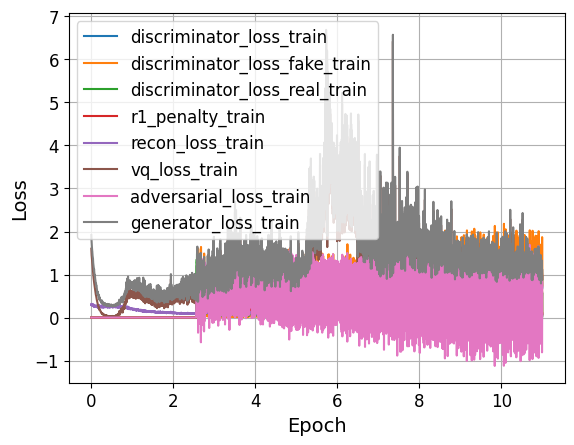

Training epoch 12:   0%|          | 0/391 [00:00<?, ?it/s]

In [ ]:
# ====
# your code
# choose these parameters
BATCH_SIZE = 
EPOCHS = 
LR = 
RECON_SCALE = 
N_CHANNELS = 
ADV_WEIGHT = # consider small value here
R1_WEIGHT = 
DISC_START = # don't perform warmup for a lot of epochs (10% of total is ok)

NUM_EMB = 
EMB_DIM = 
NUM_HEADS = 
NUM_LAYERS = 
# ====

model = VQGAN(
    num_channels=3,
    image_shape=(32, 32),
    patch_shape=(4, 4),
    num_embeddings=NUM_EMB,
    embed_dim=EMB_DIM, 
    num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS,
    recon_loss_scale=RECON_SCALE,
    n_channels=N_CHANNELS,
    adversarial_weight=ADV_WEIGHT,
    r1_weight=R1_WEIGHT,
    discriminator_start=DISC_START,
).to(DEVICE)

# we center the data, because it helps the model to fit
centered_train_data = train_data * 2 - 1
centered_test_data = test_data * 2 - 1

train_loader = data.DataLoader(centered_train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = data.DataLoader(centered_test_data, batch_size=BATCH_SIZE)

# choose any optimizer/scheduler as you want
generator_optimizer = torch.optim.Adam(
    list(model.encoder.parameters()) + list(model.vq_layer.parameters())
    + list(model.decoder.parameters()), lr=LR, betas=(0.0, 0.99)
)
discriminator_optimizer = torch.optim.Adam(
    model.discriminator.parameters(), lr=LR, betas=(0.0, 0.99)
)

train_adversarial(
    model,
    train_loader,
    epochs=EPOCHS,
    d_steps=1,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer,
    device=DEVICE,
    generator_loss_key="generator_loss",
    discriminator_loss_key="discriminator_loss",
    generator_uses_batch=True,
    visualize_samples=False,
)

Now we can visualize model samples and image reconstructions.

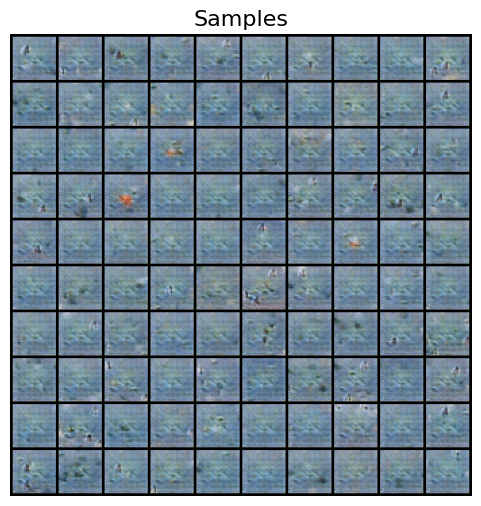

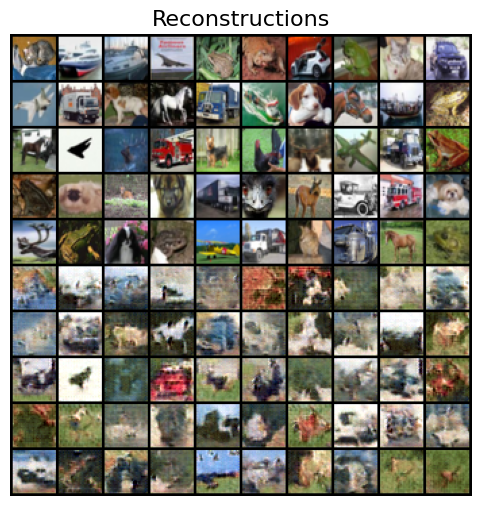

In [14]:
# Samples
samples = model.sample(100)
show_samples(samples, title="Samples")

# Reconstructions
x = torch.from_numpy(centered_test_data[:50]).to(model.device)
with torch.no_grad():
    x_recon, _ = model(x)

x = torch.clamp(x, -1, 1) * 0.5 + 0.5
x_recon = torch.clamp(x_recon, -1, 1) * 0.5 + 0.5

x_recon = x_recon.cpu().numpy()
x = x.cpu().numpy()

reconstructions = np.concatenate((x, x_recon), axis=0)
reconstructions = reconstructions.astype("float32")
show_samples(reconstructions, title="Reconstructions")

### Training of prior autoregressive model

As in Homework 2, sampling code indices from the Uniform distribution may give poor samples. To improve sample quality, we will train an autoregressive model in the latent space, keeping VQGAN fixed.

We will use a GPT model with batch-first masked multi-head attention.

In [ ]:
class MultiheadAttention(nn.MultiheadAttention):
    def __init__(
        self, 
        embed_dim: int, 
        num_heads: int, 
        batch_first: bool = True
    ) -> None:
        super().__init__(embed_dim, num_heads, batch_first=batch_first)

    def get_attention_mask(self, x: torch.Tensor) -> torch.Tensor:
        # ====
        # your code
        # define attention mask, it should contain
        # 1) zeros under and on the main diagonal
        # 2) minus Inf above the main diagonal
        
        # ====
        return attention_mask

    def forward(
        self, 
        query: torch.Tensor,
        key: torch.Tensor,
        value: torch.Tensor,
        key_padding_mask: Optional[torch.Tensor] = None,
        need_weights: bool = True,
        attn_mask: Optional[torch.Tensor] = None,
        average_attn_weights: bool = True,
        is_causal: bool = False
    ) -> Tuple[torch.Tensor, ...]:
        mask = self.get_attention_mask(query)
        return super().forward(
            query, key, value,
            attn_mask=mask,
            key_padding_mask=key_padding_mask,
            need_weights=need_weights,
            average_attn_weights=average_attn_weights,
            is_causal=is_causal
        )


def test_attention_mask() -> None:
    x = torch.zeros(4, 2, 16)
    mask = np.array([[0.0, -np.inf], [0.0, 0.0]])
    layer = MultiheadAttention(16, 8)
    attention_mask = layer.get_attention_mask(x)

    assert attention_mask.size() == (x.shape[1], x.shape[1]), \
        "Attention mask must be square with shape (seq_len, seq_len)."

    assert np.allclose(attention_mask.detach().cpu().numpy(), mask), \
        "Mask must be 0 on/under diagonal and -inf strictly above diagonal."

    out, _ = layer(x, x, x, need_weights=False)

    assert x.size() == out.size(), \
        "MultiheadAttention output must have the same shape as the input (batch_size, seq_len, embed_dim)."


test_attention_mask()

In [ ]:
class GPT(BaseModel):
    def __init__(
        self, 
        dim: int, 
        num_embeddings: int, 
        embed_dim: int, 
        num_heads: int, 
        num_layers: int
    ) -> None:
        super().__init__()

        self.dim = dim
        self.num_embeddings = num_embeddings
        self.embed_dim = embed_dim
        self.criterion = nn.CrossEntropyLoss()

        # "start of sequence" token (we initialize it from Normal distribution)
        self.sos = nn.Parameter(0.02 * torch.randn(embed_dim))
        
        # ====
        # your code
        # 1) define token_embeddings (we will have `num_embeddings` embeddings in total)
        # 2) define position_embeddings (we will use nn.Embedding)
        
        # ====

        # ====
        # your code
        # 1) create tranformers using `TransformerBlock`
        # 2) define last LayerNorm
        # 3) define final Linear layer (without bias)
        # NOTE: pass our masked MultiheadAttention to TransformerBlock
        
        # ====

    def add_sos_token(self, embeddings: torch.Tensor) -> torch.Tensor:
        batch_size = embeddings.shape[0]
        # ====
        # your code
        # prepend sos (start of sequence) token
        # 1) repeat sos token batch_size times (make it of size (batch_size, 1, emd_size))
        # 2) drop last embedding from embeddings
        # 3) concat repeated sos token to embeddings (after dropping)
        
        # ====
        return embeddings

    def add_pos_embeddings(self, embeddings: torch.Tensor) -> torch.Tensor:
        length = embeddings.shape[1]
        # ====
        # your code
        # add positional embeddings
        # 1) define tensor with positions (just torch.arange) of size (length,)
        # 2) add position embeddings to initial embeddings (use .unsqueeze(0))
        
        # ====
        return embeddings

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.long()
        embeddings = self.token_embeddings(x)
        embeddings = self.add_sos_token(embeddings)
        embeddings = self.add_pos_embeddings(embeddings)

        # ====
        # your code
        # 1) apply all transformer
        # 2) apply final LayerNorm and Linear layer
        
        # ====
        return logits

    def loss(self, x: torch.Tensor) -> dict:
        logits = self(x)
        loss = self.criterion(logits.reshape(-1, self.num_embeddings), x.reshape(-1).long())
        return {"total_loss": loss}

    @torch.no_grad()
    def sample(self, n_samples: int) -> np.ndarray:
        # read sampling carefully
        samples = torch.zeros(
            n_samples, self.dim, dtype=torch.long, device=self.device
        )
        for i in range(self.dim):
            logits = self(samples)
            dist = torch.distributions.Categorical(logits=logits[:, i, :])
            samples[:, i] = dist.sample()
        return samples.cpu().numpy()


def test_gpt():
    batch_size, dim = 8, 2
    embed_dim = 12
    num_embeddings = 256

    gpt = GPT(
        dim=dim,
        num_embeddings=num_embeddings,
        embed_dim=embed_dim,
        num_heads=4,
        num_layers=2,
    )

    emb = torch.randn(batch_size, dim, embed_dim)
    out = gpt.add_sos_token(emb)

    assert torch.isclose(out[:, 0, :], gpt.sos).all(), \
        "First token must equal the SOS embedding for every batch element."
    assert torch.allclose(out[:, 1:, :], emb[:, :-1, :]), \
        "Sequence must be shifted right by 1."

    with torch.no_grad():
        for p in range(dim):
            gpt.position_embeddings.weight[p].fill_(float(p))

    emb = torch.zeros(batch_size, dim, embed_dim)
    out = gpt.add_pos_embeddings(emb)

    for p in range(dim):
        expected = torch.full((batch_size, embed_dim), p, dtype=emb.dtype)
        assert torch.allclose(out[:, p, :], expected), (
            f"Position {p} must add a vector filled with {p} to all batch elements."
        )

    x = torch.randint(0, num_embeddings, size=(batch_size, dim))
    assert gpt(x).shape == torch.Size([batch_size, dim, num_embeddings]), \
        "Output must have shape (batch_size, seq_len, num_embeddings)."

test_gpt()

Now let’s prepare the indices dataset.

In [ ]:
model.eval()
LATENT_DIM = model.num_patches

# ====
# your code
# you have to get indices of the emdeddings from the VQ-VAE model for train and test data

# ====

assert isinstance(train_indices, np.ndarray)
assert isinstance(test_indices, np.ndarray)
assert train_indices.shape == (50000, LATENT_DIM), f'Wrong shapes: {tuple(train_indices.shape)} vs {(50000, LATENT_DIM)}'
assert test_indices.shape == (10000, LATENT_DIM), f'Wrong shapes: {tuple(test_indices.shape)} vs {(10000, LATENT_DIM)}'

Now we are ready to train our model.

In [ ]:
# ====
# your code
# choose these parameters
EPOCHS = 
BATCH_SIZE = 
LR = 

EMB_DIM = 
NUM_HEADS = 
NUM_LAYERS = 
# ====

prior_model = GPT(
    dim=LATENT_DIM, 
    num_embeddings=NUM_EMB, 
    embed_dim=EMB_DIM, 
    num_heads=NUM_HEADS, 
    num_layers=NUM_LAYERS
)

train_loader = data.DataLoader(train_indices, batch_size=BATCH_SIZE, shuffle=True)
test_loader = data.DataLoader(test_indices, batch_size=BATCH_SIZE)

# choose any optimizer/scheduler as you want
optimizer = torch.optim.AdamW(prior_model.parameters(), lr=LR)

train_model(
    prior_model,
    train_loader,
    test_loader,
    epochs=EPOCHS,
    optimizer=optimizer,
    device=DEVICE,
    visualize_samples=False,
    use_amp=True
)

Now we are ready to sample from our VQGAN model. This time, we sample the embedding indices from the GPT prior instead of the Uniform prior distribution.

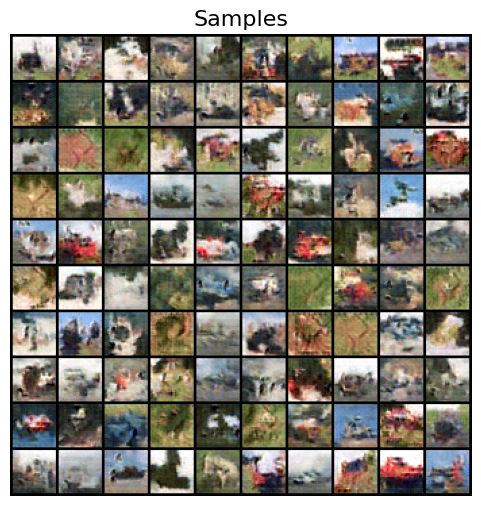

In [19]:
N_SAMPLES = 100
model.eval()
prior_model.eval()
indices = prior_model.sample(N_SAMPLES)
with torch.no_grad():
    quantized = model.vq_layer.get_quantized(
        torch.from_numpy(indices).to(model.device)
    )
    samples = 0.5 * torch.clamp(
        model.decoder(quantized), -1, 1
    ) + 0.5
    samples = samples.cpu().numpy()

samples = samples.astype("float32")
show_samples(samples, title="Samples")

## Task 3: NCSN for CIFAR-10 (6 pts)

In this task, we will implement a [Noise Conditioned Score Network (NCSN)](https://arxiv.org/abs/1907.05600). It learns the score $\nabla_x\log p_\sigma(x)$ of images corrupted with different levels of Gaussian noise. Large noise helps learn the overall distribution, while small noise captures fine details. We then generate images using Langevin dynamics with gradually decreasing noise scales.

For more intuition, see [Yang Song's blog post](https://yang-song.net/blog/2021/score/).

We will use UNet - a standart choice for all family of diffusion models. We'll begin with a simple implementation (`nn.GroupNorm` and `nn.Embedding`) and progressively enhance it with advanced components in future homeworks.

First, we'll define the UNet's core component. It is the `ResBlock`, which enhances standard ResNet blocks with timestep embeddings.

In [ ]:
class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, t_dim, dropout):
        super().__init__()
             
        self.temb_proj = nn.Sequential(nn.SiLU(), nn.Linear(t_dim, out_channels))

        # ====
        # your code
        # create two convolutional blocks of nn.Sequential
        # first block should take raw input
        # second block should take the output of the first block with added time and class embeddings
        # it is preferrable to use nn.GroupNorm (~8 groups), nn.SiLU and nn.Dropout
        
        # ====

        self.shortcut = nn.Conv2d(in_channels, out_channels, kernel_size=1) if in_channels != out_channels else nn.Identity()
    
    def forward(self, x, temb):
        # ====
        # your code
        # 1) pass x through the first block
        # 2) add time embedding (unsqueeze it to the right shape)
        # 3) pass the result through the second block
        # 4) add the shortcut
        
        # ====
        return h

The `DownsampleBlock` and `UpsampleBlock` implement the UNet's characteristic encoder-decoder structure, managing resolution changes as features flow through the network.

In [ ]:
class DownsampleBlock(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        # ====
        # your code 
        # define convolutional layer that:
        # 1) does not change the number of channels
        # 2) reduces the size of the image twice
        
        # ====

    def forward(self, input_tensor: torch.Tensor, *args) -> torch.Tensor:
        # ====
        # your code
        
        # ====
        return x

class UpsampleBlock(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        # ====
        # your code 
        # define convolutional layer that:
        # 1) does not change the number of channels
        # 2) does not reduce the size of the image
        
        # ====

    def forward(self, input_tensor: torch.Tensor, *args) -> torch.Tensor:
        # ====
        # your code
        # 1) upsample the input tensor using bilinear interpolation
        # 2) pass the result through the convolutional layer
        
        # ====
        return x

Finally, we define the complete `UNet` - the neural network backbone of our diffusion model that handles both encoding and decoding with skip connections. Look at the code carefully.

In [22]:
class UNet(nn.Module):
    def __init__(
        self, 
        num_timesteps: int, 
        hidden_channels: int, 
        channel_multipliers: List[int], 
        in_channels: int = 3,
        num_blocks: int = 1,
        dropout: float = 0.1
    ):
        super().__init__()
        
        temb_dim = hidden_channels * 4
        self.time_embedding = nn.Embedding(num_timesteps, temb_dim)
        self.head = nn.Conv2d(in_channels, hidden_channels, kernel_size=3, stride=1, padding=1)
        channel_list, curr_channels = [hidden_channels], hidden_channels

        # initialization of downsample blocks
        self.downsample_blocks = nn.ModuleList()
        for idx, scale in enumerate(channel_multipliers):
            out_channels = hidden_channels * scale
            is_last = (idx == len(channel_multipliers) - 1)

            # make multiple ResBlocks at each scale
            for _ in range(num_blocks):
                # at each channel_multipliers scale we add ResBlock
                # last block has attention
                self.downsample_blocks.append(
                    ResBlock(curr_channels, out_channels, temb_dim, dropout)
                )
                curr_channels = out_channels
                channel_list.append(curr_channels)

            # add downsample block if not last block
            if not is_last:
                self.downsample_blocks.append(DownsampleBlock(curr_channels))
                channel_list.append(curr_channels)
        
        # initialization of bottleneck block
        self.bottleneck = nn.ModuleList([
            ResBlock(curr_channels, curr_channels, temb_dim, dropout),
            ResBlock(curr_channels, curr_channels, temb_dim, dropout)
        ])
        
        # initialization of upsample blocks
        self.upsample_blocks = nn.ModuleList()
        for idx, scale in reversed(list(enumerate(channel_multipliers))):
            out_channels = hidden_channels * scale
            is_first, is_last = (idx == 0), (idx == len(channel_multipliers) - 1)

            # make multiple ResBlocks at each scale
            for _ in range(num_blocks + 1):
                # at each reverse channel_multipliers scale we add ResBlock
                # first block has attention
                self.upsample_blocks.append(
                    ResBlock(channel_list.pop() + curr_channels, out_channels, temb_dim, dropout)
                )
            
                curr_channels = out_channels
            
            # add upsample block if not last block
            if not is_first:
                self.upsample_blocks.append(UpsampleBlock(curr_channels))
                
        self.tail = nn.Sequential(
            nn.GroupNorm(8, curr_channels),
            nn.SiLU(),
            nn.Conv2d(curr_channels, in_channels, kernel_size=3, stride=1, padding=1)
        )

    def forward(self, x, t):
        temb = self.time_embedding(t)

        h = self.head(x)
        skip_connections = [h] # save intermediate results for skip connections

        # downsample
        for layer in self.downsample_blocks:
            h = layer(h, temb)
            skip_connections.append(h) # save intermediate results for skip connections

        # bottleneck
        for layer in self.bottleneck:
            h = layer(h, temb)
        
        # upsample
        for layer in self.upsample_blocks:
            if isinstance(layer, ResBlock): # apply skip connection
                skip_connection = skip_connections.pop()
                h = torch.cat([h, skip_connection], dim=1)
            h = layer(h, temb)

        h = self.tail(h)
        return h

def test_unet():
    model = UNet(
        num_timesteps=10, 
        hidden_channels=128, 
        channel_multipliers=[1, 2, 4],
        num_blocks=2 
    )
    x = torch.rand((2, 3, 32, 32))
    t = torch.zeros(size=(2,), dtype=torch.long)
    out1 = model(x, t)
    t = torch.ones(size=(2,), dtype=torch.long)
    out2 = model(x, t)
    assert not np.allclose(out1.detach().numpy(), out2.detach().numpy())


test_unet()

Now lets define the main model.

We will use the sequence of the noise levels: $\sigma_1 < \sigma_2 < \dots < \sigma_T$. In this task it will be the geometric progression.
And we will perturb the original data with the different noise levels to obtain 
$$
\mathbf{x}_t = \mathbf{x} + \sigma_t \cdot \boldsymbol{\epsilon}, \quad \mathbf{x}_t \sim q(\mathbf{x}_t). 
$$

Our **training objective**:
$$
    \sum_{t=1}^T \frac{\sigma_t^2}{\sigma_T^2} \mathbb{E}_{\pi(\mathbf{x})} \mathbb{E}_{q(\mathbf{x}_t | \mathbf{x})}\bigl\| \mathbf{s}_{\boldsymbol{\theta}, \sigma_t}(\mathbf{x}_t) - \nabla_{\mathbf{x}_{\sigma}} \log q(\mathbf{x}_t | \mathbf{x}) \bigr\|^2_2 \rightarrow \min_{\boldsymbol{\theta}}
$$
But instead of doing the honest summation we will sample one timestamp for each sample.

To **sample** from the model, we will use annealed Langevin dynamics:
1. Sample $\mathbf{x}_0 \sim \mathcal{N}(0, \sigma_T^2 \cdot \mathbf{I}) \approx q(\mathbf{x}_T)$.
2. Apply $L$ steps of Langevin dynamic
$$
    \mathbf{x}_l = \mathbf{x}_{l-1} + \frac{\eta_t}{2} \cdot \mathbf{s}_{\boldsymbol{\theta}, \sigma_t}(\mathbf{x}_{l - 1}) + \sqrt{\eta_t} \cdot \boldsymbol{\epsilon}_l.
$$
3. Update $\mathbf{x}_0 := \mathbf{x}_L$ and choose the next $\sigma_t$.
4. Repeat it for all sigmas.

**NOTE:** use the following formula for $\eta_t = \epsilon \cdot \frac{\sigma_t^2}{\sigma_T^2}$ ($\epsilon$ is a small number that is a hyperparameter of the sampling).

In [ ]:
class NoiseConditionedScoreNetwork(BaseModel):
    def __init__(
            self,
            input_shape: Tuple[int, int],
            sigmas: List[float],
            hidden_channels: int,
            channel_multipliers: List[int],
            num_blocks: int
        ):
        super().__init__()

        self.score_model = UNet(
            num_timesteps=len(sigmas), 
            hidden_channels=hidden_channels, 
            channel_multipliers=channel_multipliers, 
            num_blocks=num_blocks,
            in_channels=input_shape[0]
        )
        self.input_shape = input_shape
        self.sigmas = torch.FloatTensor(sorted(sigmas, reverse=True))

    def forward(self, x: torch.Tensor):
        self.sigmas = self.sigmas.to(self.device)
        batch_size = x.shape[0]
        # ====
        # your code
        # sample gaussian noise
        # sample timestamps for each datapoint in the batch
        # choose sigmas for these datapoints
        # add noises to the x samples
        
        # =====

        # calculate the score model
        s = self.score_model(noisy_x, which_sigmas)

        # ====
        # your code
        # compute the loss
        # it is mse between score function and gradient of the normal distribution (do not forget the coefficient before the mse)
        
        # =====
        return loss

    def loss(self, x: torch.Tensor):
        return {"total_loss": self(x).mean(dim=0).sum()}

    def annealed_langevin_dynamics(self, x: torch.Tensor, num_steps: int, eps: float):
        # =====
        # your code
        # here we will have 2 cycles: one for sigmas, one for Langevin sampling
        # start with the largest sigma, apply Langevin dynamic for it and move to the next sigma
        
        # =====
        return x
    @torch.no_grad()
    def sample(self, num_samples: int = 64, num_steps: int=10, eps: float = 0.1):
        # we sample x_0 from U[-1, 1]
        # x0 = 2. * torch.rand_like(torch.empty(num_samples, *self.input_shape)) - 1.
        x0 = torch.randn(num_samples, *self.input_shape, device=self.device) * self.sigmas[0]
        x0 = x0.to(self.device)

        # run langevine dynamics
        x = self.annealed_langevin_dynamics(x0, num_steps=num_steps, eps=eps)
        return (x.clip(-1., 1) + 1) / 2


def test_ncsn():
    ncsn = NoiseConditionedScoreNetwork(
        input_shape=(1, 8, 8),
        sigmas=[0.1],
        hidden_channels=64,
        channel_multipliers=[1, 2],
        num_blocks=1
    )
    x = torch.rand((2, 1, 8, 8))
    assert x.size() == ncsn(x).size()
    loss = ncsn.loss(x)["total_loss"]
    assert len(loss.size()) == 0
    assert list(ncsn.sample(4).size()) == [4, 1, 8, 8]


test_ncsn()

Epoch: 100, loss: 355.86198154068967


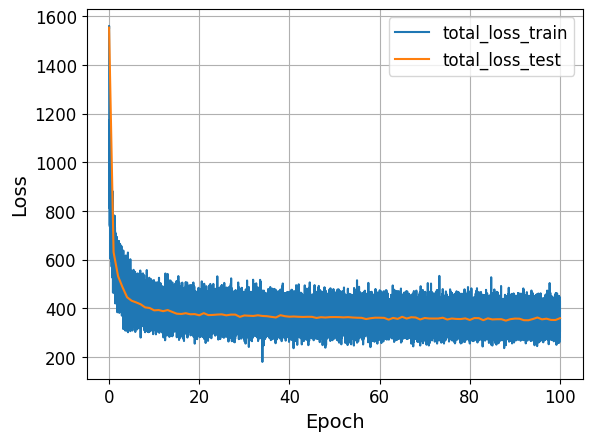

End of the training


In [ ]:
# ====
# your code
# choose these parameters
BATCH_SIZE = 
LR = 
EPOCHS = 
HIDDEN_CHANNELS = 
CHANNEL_MULTIPLIERS = 
NUM_BLOCKS = 

sigma_max = 
sigma_min = 
L = 
SIGMAS = 
# ====

centered_train_data = train_data * 2 - 1
centered_test_data = test_data * 2 - 1
train_loader = data.DataLoader(centered_train_data, batch_size=BATCH_SIZE, shuffle=True)
test_loader = data.DataLoader(centered_test_data, batch_size=BATCH_SIZE, shuffle=False)

ncsn = NoiseConditionedScoreNetwork(
    input_shape=(3, 32, 32), sigmas=SIGMAS, 
    hidden_channels=HIDDEN_CHANNELS, 
    channel_multipliers=CHANNEL_MULTIPLIERS,
    num_blocks=NUM_BLOCKS
)

# choose any optimizer/scheduler as you want
optimizer = torch.optim.AdamW(ncsn.parameters(), lr=LR, betas=(0.9, 0.999), weight_decay=1e-3)

# train
train_model(
    ncsn,
    train_loader,
    test_loader,
    epochs=EPOCHS,
    optimizer=optimizer,
    device=DEVICE,
    n_samples=16,
    visualize_samples=False, # probably you don't want to visualize samples, since it takes a lot of time
    use_amp=True
)

Now try tuning the sampling parameters to obtain better images. You can reuse the trained model without retraining it for each choice.

Unfortunately, inference with this class of models is computationally intensive and slow. Generating 100 images requires approximately 5 minutes on a GTX 1080 Ti GPU :(

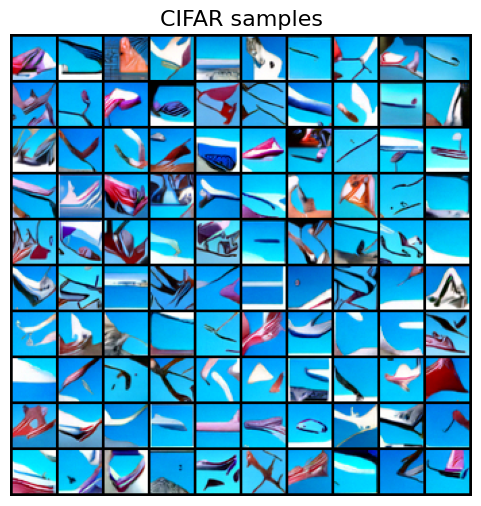

In [ ]:
# ====
# your code
# choose these parameters
NUM_STEPS = 
EPS = 
# ====

samples = ncsn.sample(100, num_steps=NUM_STEPS, eps=EPS).cpu()
show_samples(samples, "CIFAR samples")